# Project 1 — Celebrity Detection
## Milestone 4: Integrated Pipeline & Final Deliverables

**IE 7615** — Project 1, Milestone 4

**David Fung**

This milestone integrates the Milestone 1 ResNet50 classifier with the Milestone 3 YOLOv8 detector into a single end-to-end pipeline. The system accepts an input image, detects all celebrity faces, identifies each one, and returns annotated results with bounding boxes, identity labels, and confidence scores. A final results gallery is curated, and the repository is prepared for submission.


## Task 1: Environment & Imports

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob

from tensorflow.keras.applications.resnet50 import preprocess_input 
from keras.src.utils import python_utils
python_utils.preprocess_input = preprocess_input

import ultralytics
from ultralytics import YOLO
import torch

import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

print(f"Ultralytics: {ultralytics.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"TensorFlow: {tf.__version__}")


Ultralytics: 8.4.163
PyTorch: 2.14.0+cpu
TensorFlow: 2.19.0


In [3]:
# PROJECT CONSTANTS
GLOBAL_SEED = 42
np.random.seed(GLOBAL_SEED)
tf.keras.utils.set_random_seed(GLOBAL_SEED)

SCRIPT_DIR = os.path.abspath(os.getcwd())
ROOT = os.path.abspath(os.path.join(SCRIPT_DIR, ".."))

# Base Model
CLASSIFIER_PATH = os.path.join(SCRIPT_DIR, "models", "resnet50_classifier.keras")
CLASS_NAMES_5 = ["7", "797", "2619", "4428", "7007"]

# Improved Model
CLASSIFIER_IMP_PATH = os.path.join(SCRIPT_DIR, "models", "resnet50_classifier_improved.keras")
CLASS_NAMES_13 = ["3", "7", "797", "1212", "2336", "2619", "2970", "4422", "4428", "5695", "7007", "8335", "10002"]

TARGET_IDS = {"7", "797", "2619", "4428", "7007"}

NUM_CLASSES_DET = 13
NUM_CLASSES_CLS = 5
# Detection confidence kept low so faces are not missed (important for
# unseen images during the live demo). Raise CONF (e.g. 0.25) to be more
# conservative. ID_THRESH gates whether the classifier identity is accepted.
CONF = 0.1
ID_THRESH = 0.5
IMGSZ = 640

print(f"Classifier: {CLASSIFIER_PATH}")
print(f"Classifier classes: {CLASS_NAMES_5}")
print(f"Target IDs: {sorted(TARGET_IDS)}")


Classifier: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_4\models\resnet50_classifier.keras
Classifier classes: ['7', '797', '2619', '4428', '7007']
Target IDs: ['2619', '4428', '7', '7007', '797']


## Task 2: Load Models

In [4]:
# Load YOLOv8 detection model (from Milestone 3)
DET_PATH = os.path.join(ROOT, "Milestone_3", "runs", "detect",
                        "celebrity_detection", "yolov8n_finetune", "weights", "best.pt")
det_model = YOLO(DET_PATH)
det_names = det_model.names
print(f"Detector classes ({NUM_CLASSES_DET}): {list(det_names.values())}")

Detector classes (13): ['3', '7', '797', '1212', '2336', '2619', '2970', '4422', '4428', '5695', '7007', '8335', '10002']


In [5]:
# Load ResNet50 classification model (from Milestone 4 training)
cls_model = tf.keras.models.load_model(CLASSIFIER_PATH, compile=False, safe_mode=False)
cls_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness_1             │ (None, 224, 224, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,541 (91.99 MB)

 Trainable params: 4,991,493 (19.04 MB)

 Non-trainable params: 19,122,048 (72.94 MB)

In [6]:
# Load Imrpvoed ResNet50 classification model (from Milestone 4 training)
cls_model_imp = tf.keras.models.load_model(CLASSIFIER_IMP_PATH, compile=False, safe_mode=False)
cls_model_imp.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness_1             │ (None, 224, 224, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 13)             │         3,341 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,773,517 (94.50 MB)

 Trainable params: 5,650,445 (21.55 MB)

 Non-trainable params: 19,123,072 (72.95 MB)

## Task 3: Integrated Pipeline

In [7]:
def run_pipeline(image_path, conf=CONF, imgsz=IMGSZ, id_thresh=ID_THRESH):
    """Run the full celebrity-identification pipeline on a single image.

    1. YOLOv8 detects faces (13-class) with confidence.
    2. Every detected face is cropped and passed to the ResNet50 (5-class) identifier.
    3. If the identifier is confident (top prob >= id_thresh) its label is used
       (source = "classifier"); otherwise the detector label is kept
       (source = "detector"). This guarantees a box is always returned.
    """
    import cv2
    results = []
    img = det_model(source=image_path, conf=conf, imgsz=imgsz, verbose=False)[0]
    boxes = img.boxes
    full_img = img.orig_img
    for i in range(len(boxes)):
        x1, y1, x2, y2 = map(int, boxes.xyxy[i].tolist())
        det_label = str(det_names[int(boxes.cls[i].item())])
        det_conf = float(boxes.conf[i].item())
        cls_label, cls_conf, source = det_label, det_conf, "detector"
        face_arr = full_img[y1:y2, x1:x2]
        if face_arr is not None and face_arr.size > 0:
            resized = cv2.resize(face_arr, (224, 224))
            arr = resized.astype(np.float32)[np.newaxis, ...]
            probs = cls_model.predict(arr, verbose=0)[0]
            cls_idx = int(np.argmax(probs))
            cls_conf_val = float(probs[cls_idx])
            if cls_conf_val >= id_thresh:
                cls_label = CLASS_NAMES_5[cls_idx]
                cls_conf = cls_conf_val
                source = "classifier"
        results.append({"label": cls_label, "confidence": cls_conf,
                        "bbox": [x1, y1, x2, y2], "source": source,
                        "is_target": det_label in TARGET_IDS})
    return results


In [8]:
# For improved model 

def run_pipeline_imp(image_path, conf=CONF, imgsz=IMGSZ, id_thresh=ID_THRESH):
    """Run the full celebrity-identification pipeline on a single image.

    1. YOLOv8 detects faces (13-class) with confidence.
    2. Every detected face is cropped and passed to the ResNet50 (5-class) identifier.
    3. If the identifier is confident (top prob >= id_thresh) its label is used
       (source = "classifier"); otherwise the detector label is kept
       (source = "detector"). This guarantees a box is always returned.
    """
    import cv2
    results = []
    img = det_model(source=image_path, conf=conf, imgsz=imgsz, verbose=False)[0]
    boxes = img.boxes
    full_img = img.orig_img
    for i in range(len(boxes)):
        x1, y1, x2, y2 = map(int, boxes.xyxy[i].tolist())
        det_label = str(det_names[int(boxes.cls[i].item())])
        det_conf = float(boxes.conf[i].item())
        cls_label, cls_conf, source = det_label, det_conf, "detector"
        face_arr = full_img[y1:y2, x1:x2]
        if face_arr is not None and face_arr.size > 0:
            resized = cv2.resize(face_arr, (224, 224))
            arr = resized.astype(np.float32)[np.newaxis, ...]
            probs = cls_model_imp.predict(arr, verbose=0)[0]
            cls_idx = int(np.argmax(probs))
            cls_conf_val = float(probs[cls_idx])
            if cls_conf_val >= id_thresh:
                cls_label = CLASS_NAMES_13[cls_idx]
                cls_conf = cls_conf_val
                source = "classifier"
        results.append({"label": cls_label, "confidence": cls_conf,
                        "bbox": [x1, y1, x2, y2], "source": source,
                        "is_target": det_label in TARGET_IDS})
    return results


## Task 4: Run Pipeline on Test Images

In [9]:
test_dir = os.path.join(ROOT, "data", "synthetic_grid", "images", "test")
test_files = sorted(glob.glob(os.path.join(test_dir, "*.jpg")))

print(f"Test images: {len(test_files)}")
all_results = {}
for f in test_files:
    res = run_pipeline(f)
    all_results[f] = res
    n_cls = sum(1 for r in res if r["source"] == "classifier")
    n_det = sum(1 for r in res if r["source"] == "detector")
    print(f"  {os.path.basename(f)}: {len(res)} faces (Baseline Model: {n_cls} classified, {n_det} from detector)")
    for r in res:
        mark = " *" if r["label"] not in TARGET_IDS else ""
        print(f"     {r['label']:>5}  conf={r['confidence']:.4f}  [{r['source']}]{mark}")


Test images: 3
  grid_0000.jpg: 7 faces (Baseline Model: 4 classified, 3 from detector)
      7007  conf=0.5620  [classifier]
      2970  conf=0.4830  [detector] *
      2619  conf=0.5726  [classifier]
         7  conf=0.8591  [classifier]
      7007  conf=0.5147  [classifier]
      2336  conf=0.1180  [detector] *
         7  conf=0.1134  [detector]
  grid_0005.jpg: 8 faces (Baseline Model: 7 classified, 1 from detector)
      7007  conf=0.9929  [classifier]
         7  conf=0.7070  [classifier]
      7007  conf=0.9671  [classifier]
       797  conf=0.3206  [detector]
      2619  conf=0.8609  [classifier]
       797  conf=0.5024  [classifier]
      7007  conf=0.9938  [classifier]
         7  conf=0.7711  [classifier]
  grid_0017.jpg: 10 faces (Baseline Model: 10 classified, 0 from detector)
       797  conf=0.6337  [classifier]
      7007  conf=0.5847  [classifier]
      7007  conf=0.7440  [classifier]
      7007  conf=0.8104  [classifier]
      7007  conf=0.7671  [classifier]
        

In [10]:
# Run with Improved model

#test_dir = os.path.join(ROOT, "data", "synthetic_grid", "images", "test")
#test_files = sorted(glob.glob(os.path.join(test_dir, "*.jpg")))
print(f"Test images: {len(test_files)}")
all_results_imp = {}
for f in test_files:
    res = run_pipeline_imp(f)
    all_results_imp[f] = res
    n_cls = sum(1 for r in res if r["source"] == "classifier")
    n_det = sum(1 for r in res if r["source"] == "detector")
    print(f"  {os.path.basename(f)}: {len(res)} faces (Improved Model: {n_cls} classified, {n_det} from detector)")
    for r in res:
        mark = " *" if r["label"] not in TARGET_IDS else ""
        print(f"     {r['label']:>5}  conf={r['confidence']:.4f}  [{r['source']}]{mark}")

Test images: 3
  grid_0000.jpg: 7 faces (Improved Model: 7 classified, 0 from detector)
       797  conf=0.9457  [classifier]
      4422  conf=0.5229  [classifier] *
      8335  conf=0.9653  [classifier] *
      1212  conf=0.9930  [classifier] *
      4422  conf=0.6698  [classifier] *
         3  conf=0.9988  [classifier] *
         3  conf=0.9991  [classifier] *
  grid_0005.jpg: 8 faces (Improved Model: 7 classified, 1 from detector)
      4422  conf=0.6889  [classifier] *
      1212  conf=0.9936  [classifier] *
     10002  conf=0.8891  [classifier] *
       797  conf=0.6981  [classifier]
      8335  conf=0.2959  [detector] *
         3  conf=0.8541  [classifier] *
      4422  conf=0.7468  [classifier] *
      1212  conf=0.9980  [classifier] *
  grid_0017.jpg: 10 faces (Improved Model: 9 classified, 1 from detector)
       797  conf=0.5814  [classifier]
       797  conf=0.7415  [detector]
      4422  conf=0.9308  [classifier] *
     10002  conf=0.8248  [classifier] *
     10002  conf=

## Task 5: Visualization

In [11]:
import cv2
def visualize_result(image_path, results, save_path=None):
    """Draw bounding boxes with labels.
    Green (classifier): label above the box.
    Orange (detector): label inside box, bottom-left.
    """
    img = cv2.imread(image_path)
    for r in results:
        x1, y1, x2, y2 = r["bbox"]
        colorb = (0, 200, 0) if r["source"] == "classifier" else (255, 140, 0)
        cv2.rectangle(img, (x1, y1), (x2, y2), colorb, 2)
        text = f"{r['label']} ({r['confidence']:.2f})"
        if r["source"] == "classifier":
            (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
            cv2.rectangle(img, (x1, y1 - th - 6), (x1 + tw, y1), colorb, -1)
            cv2.putText(img, text, (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1)
        else:
            cv2.putText(img, text, (x1 + 3, y2 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, colorb, 1)
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        cv2.imwrite(save_path, img)
    return img



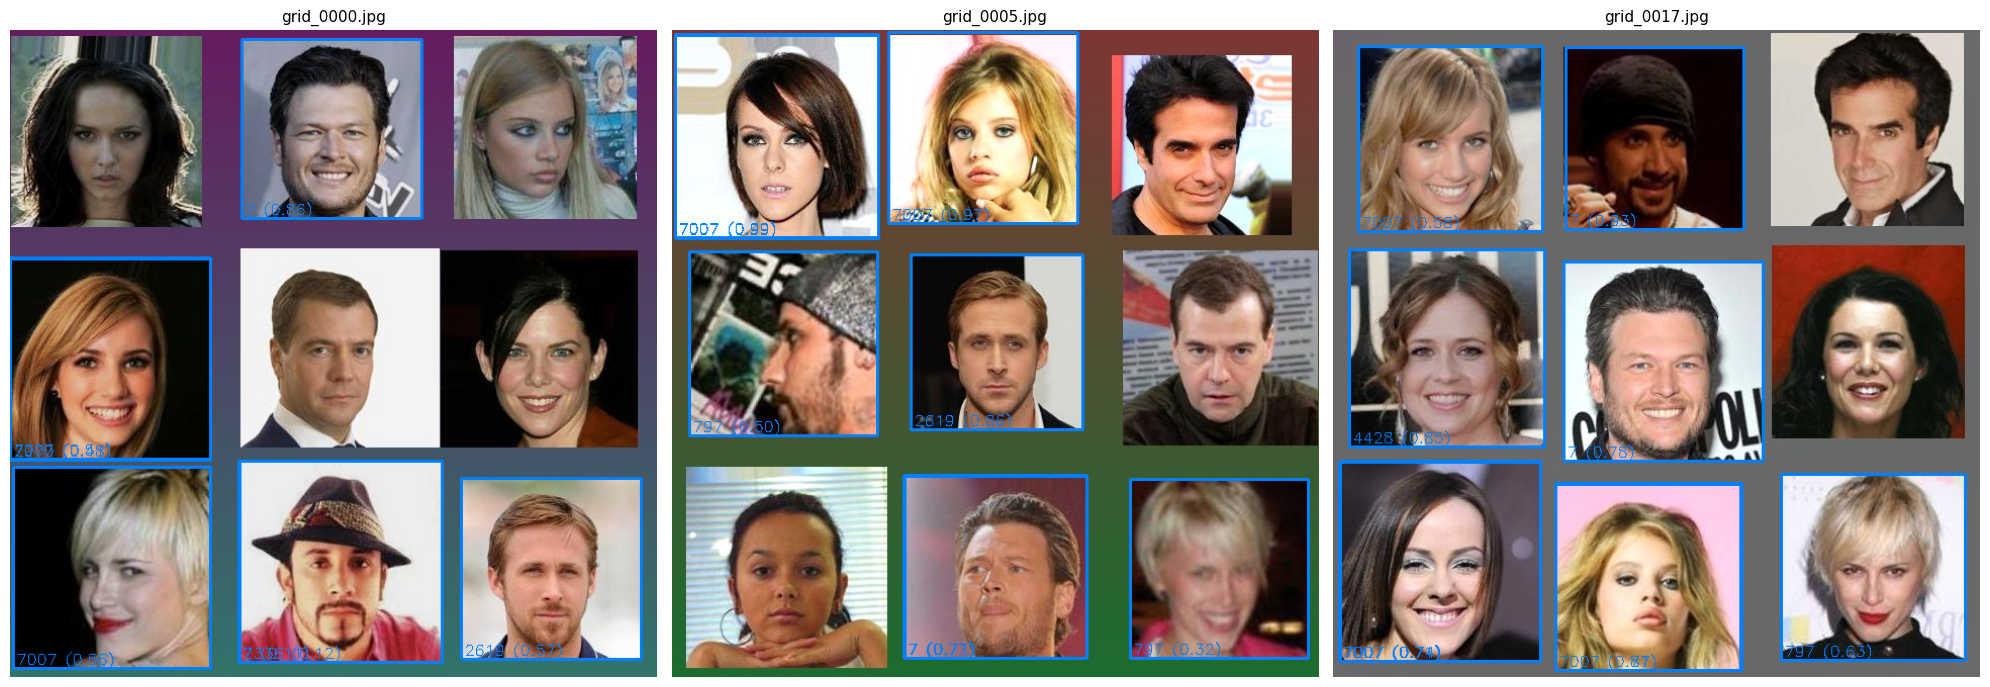

In [12]:
vis_dir = os.path.join(SCRIPT_DIR, "pipeline_output")
os.makedirs(vis_dir, exist_ok=True)
for f, res in all_results.items():
    visualize_result(f, res, os.path.join(vis_dir, os.path.basename(f)))

fig, axes = plt.subplots(1, min(3, len(all_results)), figsize=(20, 8))
if len(all_results) == 1: axes = [axes]
for ax, (f, res) in zip(axes, list(all_results.items())[:3]):
    img = cv2.imread(f)
    for r in res:
        x1, y1, x2, y2 = r["bbox"]
        color = (0, 255, 0) if r["source"] == "cls" else (255, 128, 0)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        text = f"{r['label']} ({r['confidence']:.2f})"
        if r["source"] == "cls":
            (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
            cv2.rectangle(img, (x1, y1 - th - 6), (x1 + tw, y1), color, -1)
            cv2.putText(img, text, (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1)
        else:
            cv2.putText(img, text, (x1 + 3, y2 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(os.path.basename(f), fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(SCRIPT_DIR, "pipeline_summary.png"), dpi=150, bbox_inches="tight")
plt.show()


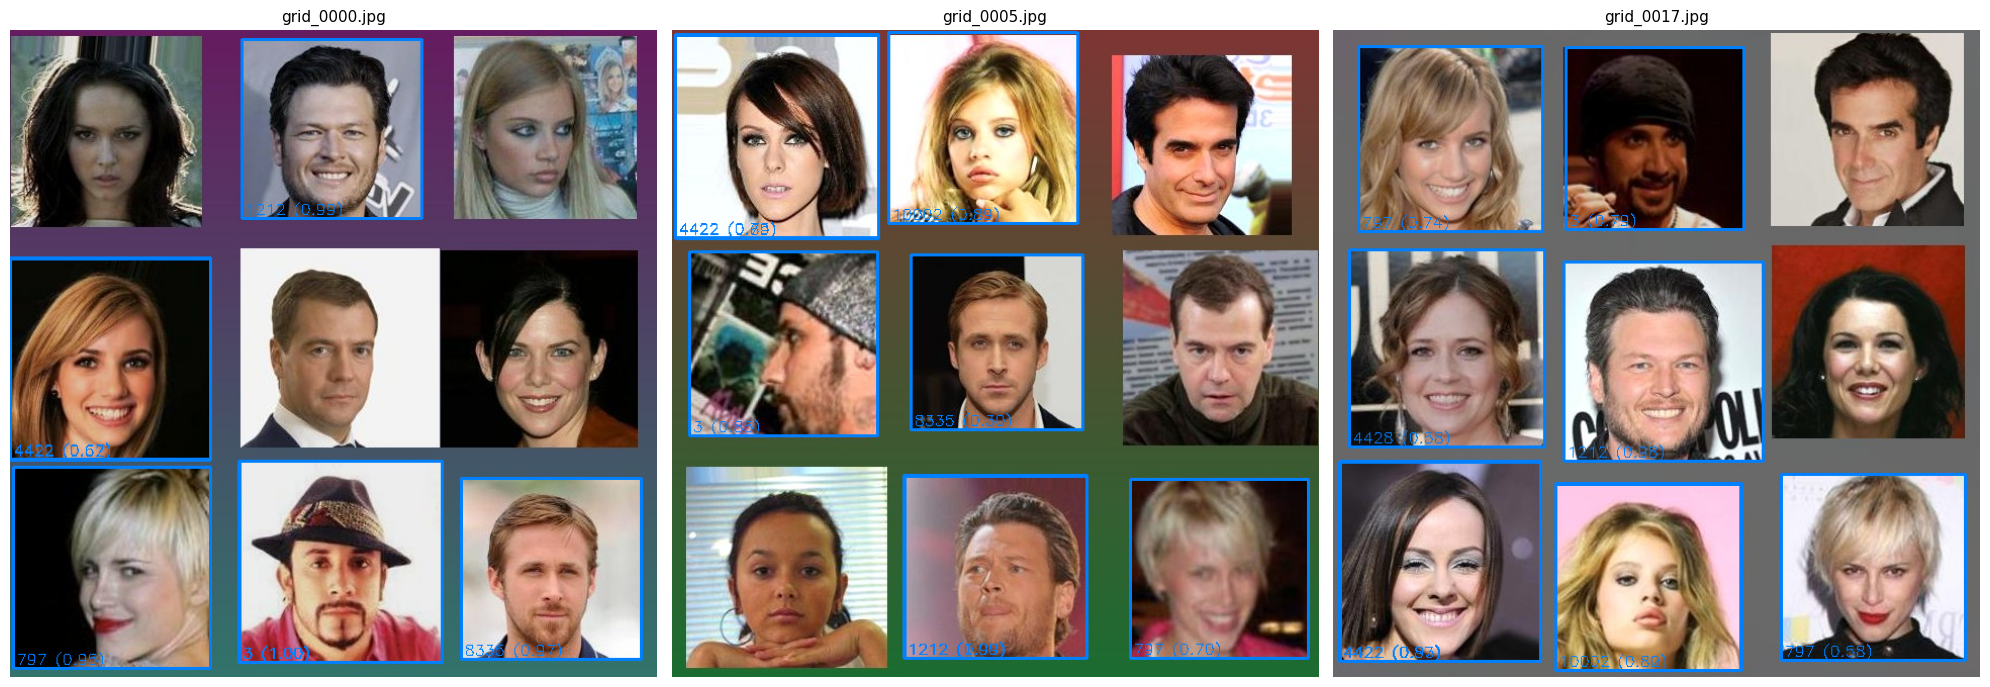

In [13]:
# Improved Model

vis_dir = os.path.join(SCRIPT_DIR, "pipeline_output_improved")
os.makedirs(vis_dir, exist_ok=True)
for f, res in all_results_imp.items():
    visualize_result(f, res, os.path.join(vis_dir, os.path.basename(f)))

fig, axes = plt.subplots(1, min(3, len(all_results_imp)), figsize=(20, 8))
if len(all_results_imp) == 1: axes = [axes]
for ax, (f, res) in zip(axes, list(all_results_imp.items())[:3]):
    img = cv2.imread(f)
    for r in res:
        x1, y1, x2, y2 = r["bbox"]
        color = (0, 255, 0) if r["source"] == "cls" else (255, 128, 0)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        text = f"{r['label']} ({r['confidence']:.2f})"
        if r["source"] == "cls":
            (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
            cv2.rectangle(img, (x1, y1 - th - 6), (x1 + tw, y1), color, -1)
            cv2.putText(img, text, (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1)
        else:
            cv2.putText(img, text, (x1 + 3, y2 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(os.path.basename(f), fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(SCRIPT_DIR, "pipeline_summary_imp.png"), dpi=150, bbox_inches="tight")
plt.show()


## Task 6: Results Gallery

In [14]:
gallery_dir = os.path.join(SCRIPT_DIR, "gallery")
n_correct = len(os.listdir(os.path.join(gallery_dir, "classification_correct")))
n_errors = len(os.listdir(os.path.join(gallery_dir, "classification_errors")))
n_det = len(os.listdir(os.path.join(gallery_dir, "detection")))
print(f"Baseline Gallery: {n_correct} correct + {n_errors} errors + {n_det} detection = {n_correct+n_errors+n_det} total")

# Improved
n_icorrect = len(os.listdir(os.path.join(gallery_dir, "classification_correct_improved")))
n_ierrors = len(os.listdir(os.path.join(gallery_dir, "classification_errors_improved")))
n_idet = len(os.listdir(os.path.join(gallery_dir, "detection_improved")))
print(f"Baseline Gallery: {n_icorrect} correct + {n_ierrors} errors + {n_idet} detection = {n_icorrect+n_ierrors+n_idet} total")

Baseline Gallery: 25 correct + 10 errors + 11 detection = 46 total
Baseline Gallery: 25 correct + 10 errors + 11 detection = 46 total


## Task 7: Confidence‑level comparison (original vs. improved)


In [15]:

# Comparison of the two models

print("Loading original classifier …")
orig_clf = load_model(CLASSIFIER_PATH, compile=False, safe_mode=False)
print("Loading improved classifier …")
imp_clf  = load_model(CLASSIFIER_IMP_PATH,  compile=False, safe_mode=False)

det_model = YOLO(DET_PATH)
det_names = det_model.names
print(f"Detector classes ({NUM_CLASSES_DET}): {list(det_names.values())}")

orig_names = ["7", "797", "2619", "4428", "7007"]
imp_names  = ["3", "7", "797", "1212", "2336", "2619", "2970", "4422", "4428", "5695", "7007", "8335", "10002"]

def top_prediction(model, crop):
    arr = cv2.resize(crop, (224, 224)).astype(np.float32)[np.newaxis, ...]
    probs = model.predict(arr, verbose=0)[0]
    idx   = int(np.argmax(probs))
    conf  = float(probs[idx])
    return idx, conf

test_files = sorted(glob.glob(os.path.join(test_dir, "*.jpg")))
print(f"Test images: {len(test_files)}")

records = []
for f in test_files:
    img_name = os.path.basename(f)
    img = cv2.imread(f)
    if img is None:
        continue
    results = det_model.predict(f, conf=0.1, imgsz=640, verbose=False)
    boxes = results[0].boxes
    for i, b in enumerate(boxes):
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
        h, w = img.shape[:2]
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w, x2), min(h, y2)
        crop = img[y1:y2, x1:x2]
        if crop.size == 0:
            continue
        orig_idx, orig_conf = top_prediction(orig_clf, crop)
        orig_pred = orig_names[orig_idx] if orig_idx < len(orig_names) else str(orig_idx)
        imp_idx, imp_conf = top_prediction(imp_clf, crop)
        imp_pred = imp_names[imp_idx] if imp_idx < len(imp_names) else str(imp_idx)
        records.append({
            "Image": img_name,
            "Box#": i,
            "Original_Pred": orig_pred,
            "Original_Conf": round(orig_conf, 4),
            "Improved_Pred": imp_pred,
            "Improved_Conf": round(imp_conf, 4)
        })

df = pd.DataFrame.from_records(records)
print(f"Total detected faces (boxes) across the test images: {len(df)}")
print(df.to_string(index=False))

agree = (df["Original_Pred"] == df["Improved_Pred"]).sum()
print(f"Predictions that agree on class label: {agree}/{len(df)} ({100*agree/len(df):.1f}%)")
print(f"Mean confidence – Original: {df['Original_Conf'].mean():.3f}")
print(f"Mean confidence – Improved: {df['Improved_Conf'].mean():.3f}")


Loading original classifier …
Loading improved classifier …
Detector classes (13): ['3', '7', '797', '1212', '2336', '2619', '2970', '4422', '4428', '5695', '7007', '8335', '10002']
Test images: 3
Total detected faces (boxes) across the test images: 25
        Image  Box# Original_Pred  Original_Conf Improved_Pred  Improved_Conf
grid_0000.jpg     0          7007         0.5620           797         0.9457
grid_0000.jpg     1          4428         0.4962          4422         0.5229
grid_0000.jpg     2          2619         0.5726          8335         0.9653
grid_0000.jpg     3             7         0.8591          1212         0.9930
grid_0000.jpg     4          7007         0.5147          4422         0.6698
grid_0000.jpg     5          7007         0.4211             3         0.9988
grid_0000.jpg     6          7007         0.4853             3         0.9991
grid_0005.jpg     0          7007         0.9929          4422         0.6889
grid_0005.jpg     1             7         0.7